<a href="https://colab.research.google.com/github/cs24dse023-netizen/CSL701-cs23_Machine-Learning-Lab/blob/main/ML_Experiment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name : Sandesh Kaskar

Batch : CS02


Roll Number : CS23



Aim

To implement Principal Component Analysis (PCA) for dimensionality reduction on the Breast Cancer Wisconsin (Diagnostic) dataset, visualize the high-dimensional feature space in a reduced 2D plane, and evaluate its impact on classification performance.

## Objectives

1. To understand the concepts of dimensionality reduction, feature correlation, and Principal Component Analysis.

2. To preprocess, clean, and scale high-dimensional real-world data using StandardScaler.

3. To implement PCA using Python to compress feature dimensions from 30 continuous features down to 2 principal components.

4. To calculate and plot the explained variance ratio and cumulative explained variance.

5. To visualize the transformed 2D dataset and analyze class separability.

6. To evaluate and compare classification model performance (e.g., Logistic Regression) before and after applying PCA.

# Relevant Theory

### Support Vector Machine

Principal Component Analysis (PCA)Principal Component Analysis (PCA) is an unsupervised machine learning technique used for dimensionality reduction. It transforms a dataset containing a large set of correlated features into a smaller set of uncorrelated variables called Principal Components ($PCs$), while preserving as much data variance as possible.

Mathematical Steps:

1. Standardization: Scale each feature to have a mean of 0 ($\mu = 0$) and standard deviation of 1 ($\sigma = 1$).

2. Covariance Matrix: Compute the covariance matrix $C$ to quantify feature correlations:$$C = \frac{1}{n-1} X^T X$$

3. Eigen decomposition: Compute eigenvalues ($\lambda$) and eigenvectors ($v$) of matrix $C$:$$C v = \lambda v$$

    * Eigenvectors represent the direction of the principal axes.
    * Eigenvalues indicate the amount of variance along those axes.
4. Projection: Project original data $X$ onto top $k$ principal component directions $W$:$$X_{\text{pca}} = X \cdot W$$

###Dataset Information


1. Dataset Name: Breast Cancer Wisconsin (Diagnostic) Dataset

2. Kaggle Link: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

3. Classes: 2 binary classes (Malignant [$M$] and Benign [$B$])

4. Features: 30 continuous features computed from digitized images of fine needle aspirates (FNA) of a breast mass (e.g., radius_mean, texture_mean, perimeter_mean, area_mean, smoothness_mean, concavity_mean, etc.).

5. Non-Feature Columns: id (identifier) and Unnamed: 32 (empty column).

# Task 1: Import Libraries and Load Dataset

Import core Python libraries (numpy, pandas, matplotlib, seaborn, sklearn) and load data.csv obtained from Kaggle.

---

In [3]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

# Import Scikit-learn
import sklearn

# Step 2: Upload the dataset in Google Colab
from google.colab import files
uploaded = files.upload()

# Extract the uploaded zip file if data.csv is inside it
for file_name in uploaded.keys():
    if file_name.endswith('.zip'):
        with zipfile.ZipFile(file_name, 'r') as zip_ref:
            zip_ref.extractall('.')
        print(f"Extracted contents of {file_name}")

# Step 3: Load the dataset
df = pd.read_csv('data.csv')

# Step 4: Display the first five records
print("First five records:")
display(df.head())

# Step 5: Display dataset information
print("Dataset shape (rows, columns):", df.shape)

print("\nDataset information:")
df.info()

# Step 6: Display column names
print("\nColumn names:")
print(df.columns.tolist())


Saving archive.zip to archive (2).zip
Extracted contents of archive (2).zip
First five records:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Dataset shape (rows, columns): (569, 33)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se       

# Task 2: Explore the Dataset

Inspect missing values, view dataset summary statistics, check column data types, and inspect target class distributions (diagnosis).

First five rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Dataset Shape:
(569, 33)

Column Data Types:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactne

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN



Diagnosis Class Distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis Class Percentages:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


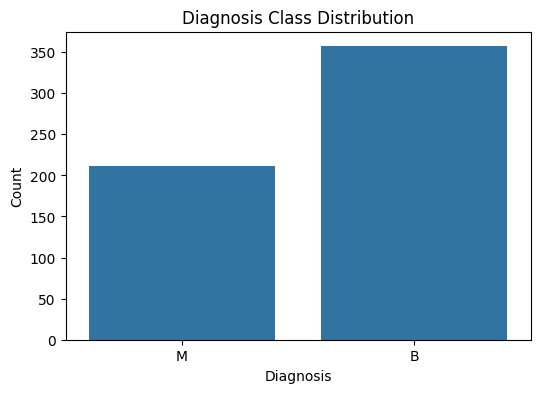

In [4]:

# Task 2: Explore the Dataset

# 1. Display first five rows
print("First five rows:")
display(df.head())

# 2. Check dataset shape
print("\nDataset Shape:")
print(df.shape)

# 3. Check column data types
print("\nColumn Data Types:")
print(df.dtypes)

# 4. Check missing values
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# 5. Summary statistics
print("\nSummary Statistics:")
display(df.describe())

# 6. Check target class distribution
print("\nDiagnosis Class Distribution:")
print(df['diagnosis'].value_counts())

# 7. Display class percentages
print("\nDiagnosis Class Percentages:")
print(df['diagnosis'].value_counts(normalize=True) * 100)

# 8. Visualize diagnosis distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='diagnosis')
plt.title('Diagnosis Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

# Task 3: Data Cleaning and Feature/Target Selection

Drop metadata columns (id and Unnamed: 32). Convert the categorical target column (diagnosis: 'M'/'B') into numerical values (1/0) and separate feature matrix $X$ (30 features) from label vector $y$.   

In [5]:

# Task 3: Data Cleaning and Feature/Target Selection

# 1. Drop unnecessary metadata columns
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

# 2. Convert diagnosis into numerical values
# M = Malignant (1), B = Benign (0)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# 3. Separate features (X) and target (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# 4. Display results
print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)

print("\nFirst five rows of X:")
display(X.head())

print("\nFirst five values of y:")
print(y.head())

print("\nTarget class distribution:")
print(y.value_counts())

# 5. Verify the number of features
print("\nNumber of features:", X.shape[1])

Feature matrix X shape: (569, 30)
Target vector y shape: (569,)

First five rows of X:


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



First five values of y:
0    1
1    1
2    1
3    1
4    1
Name: diagnosis, dtype: int64

Target class distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

Number of features: 30


# Task 4: Standardize Features

Apply StandardScaler to transform all 30 numeric features so they have zero mean and unit variance ($\mu=0, \sigma=1$).

In [6]:

# Task 4: Standardize Features

from sklearn.preprocessing import StandardScaler

# 1. Create StandardScaler object
scaler = StandardScaler()

# 2. Standardize all 30 features
X_scaled = scaler.fit_transform(X)

# 3. Convert scaled features into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

# 4. Display the first five standardized rows
print("First five rows of standardized features:")
display(X_scaled.head())

# 5. Check mean and standard deviation
print("\nMean of first five features:")
print(X_scaled.mean().head())

print("\nStandard deviation of first five features:")
print(X_scaled.std(ddof=0).head())

# 6. Check shape
print("\nStandardized feature matrix shape:", X_scaled.shape)


First five rows of standardized features:


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100



Mean of first five features:
radius_mean       -1.373633e-16
texture_mean       6.868164e-17
perimeter_mean    -1.248757e-16
area_mean         -2.185325e-16
smoothness_mean   -8.366672e-16
dtype: float64

Standard deviation of first five features:
radius_mean        1.0
texture_mean       1.0
perimeter_mean     1.0
area_mean          1.0
smoothness_mean    1.0
dtype: float64

Standardized feature matrix shape: (569, 30)


# Task 5: Implement PCA (30D to 2D)

Use sklearn.decomposition.PCA to reduce feature dimensions from 30 down to 2 principal components ($PC_1$ and $PC_2$).

In [7]:

# Task 5: Implement PCA (30D to 2D)

from sklearn.decomposition import PCA

# 1. Create PCA object with 2 principal components
pca = PCA(n_components=2)

# 2. Transform standardized features into 2D
X_pca = pca.fit_transform(X_scaled)

# 3. Convert the result into a DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2'],
    index=X_scaled.index
)

# 4. Display the first five rows
print("First five rows of PCA-transformed data:")
display(pca_df.head())

# 5. Display explained variance ratio
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# 6. Display total variance explained by two components
total_variance = pca.explained_variance_ratio_.sum()
print("\nTotal variance explained by PC1 and PC2:",
      round(total_variance * 100, 2), "%")

# 7. Display the shape
print("\nOriginal feature shape:", X_scaled.shape)
print("PCA-transformed shape:", pca_df.shape)


First five rows of PCA-transformed data:


,PC1,PC2
0,9.192837,1.948583
1,2.387802,-3.768172
2,5.733896,-1.075174
3,7.122953,10.275589
4,3.935302,-1.948072



Explained Variance Ratio:
[0.44272026 0.18971182]

Total variance explained by PC1 and PC2: 63.24 %

Original feature shape: (569, 30)
PCA-transformed shape: (569, 2)


# Task 6: Analyze Explained Variance Ratio

Compute and print the variance explained by $PC_1$ and $PC_2$, along with the cumulative variance retained.


In [8]:

# Task 6: Analyze Explained Variance Ratio

# 1. Get explained variance ratio for each component
explained_variance = pca.explained_variance_ratio_

# 2. Calculate cumulative variance
cumulative_variance = np.cumsum(explained_variance)

# 3. Print variance explained by each component
print("Variance explained by PC1:",
      round(explained_variance[0] * 100, 2), "%")

print("Variance explained by PC2:",
      round(explained_variance[1] * 100, 2), "%")

# 4. Print cumulative variance retained
print("Cumulative variance after PC1:",
      round(cumulative_variance[0] * 100, 2), "%")

print("Cumulative variance after PC2:",
      round(cumulative_variance[1] * 100, 2), "%")

# 5. Display results in a table
variance_df = pd.DataFrame({
    'Principal Component': ['PC1', 'PC2'],
    'Explained Variance (%)': explained_variance * 100,
    'Cumulative Variance (%)': cumulative_variance * 100
})

display(variance_df.round(2))


Variance explained by PC1: 44.27 %
Variance explained by PC2: 18.97 %
Cumulative variance after PC1: 44.27 %
Cumulative variance after PC2: 63.24 %


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,44.27,44.27
1,PC2,18.97,63.24


# Task 7: Visualize PCA Transformed Boundary / Scatter Plot

Create a 2D scatter plot with $PC_1$ on the x-axis and $PC_2$ on the y-axis, hue-coded by tumor diagnosis (Malignant vs. Benign).

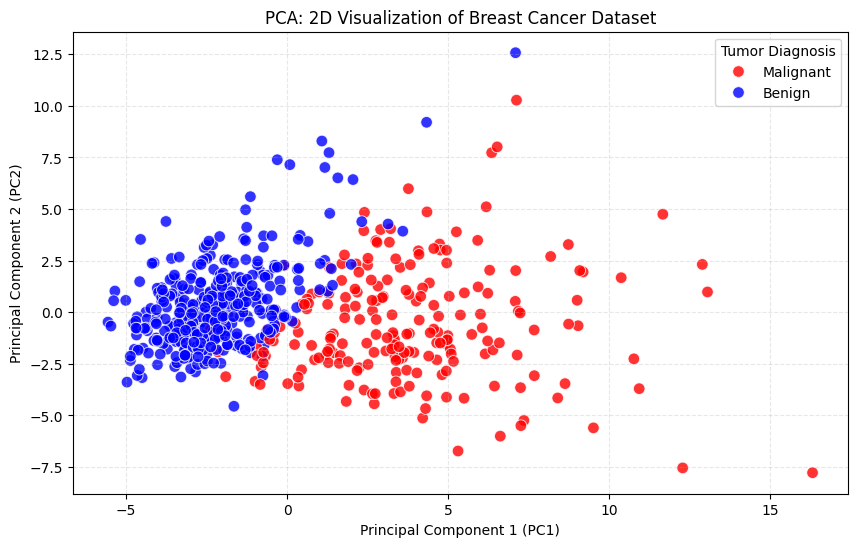

In [9]:

# Task 7: Visualize PCA Transformed Scatter Plot

# 1. Create a DataFrame with PCA components and diagnosis
plot_df = pca_df.copy()

# Convert numerical labels to diagnosis names
plot_df['Diagnosis'] = y.map({
    1: 'Malignant',
    0: 'Benign'
})

# 2. Create the scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x='PC1',
    y='PC2',
    hue='Diagnosis',
    palette={
        'Malignant': 'red',
        'Benign': 'blue'
    },
    s=70,
    alpha=0.8
)

# 3. Add title and labels
plt.title('PCA: 2D Visualization of Breast Cancer Dataset')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Tumor Diagnosis')
plt.grid(True, linestyle='--', alpha=0.3)

# 4. Display the plot
plt.show()


# Task 8: Train Classifier on Raw High-Dimensional Data (30 Features)

Split the original scaled 30-feature dataset into training and testing sets. Train a Logistic Regression model and obtain baseline performance metrics.

Training data shape: (455, 30)
Testing data shape: (114, 30)

Baseline Performance Metrics (30 Features)
------------------------------------------
Accuracy:  0.9649
Precision: 0.9750
Recall:    0.9286
F1-Score:  0.9512

Confusion Matrix:
[[71  1]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



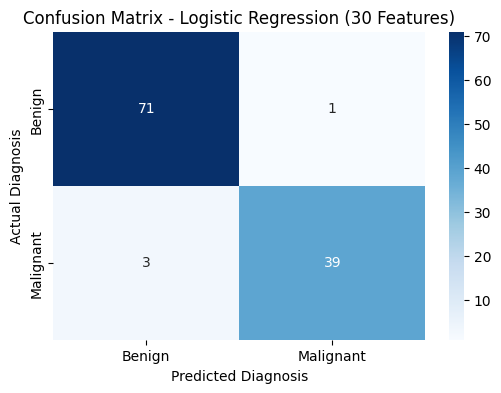

In [10]:

# Task 8: Logistic Regression on 30 Features

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Split the scaled dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# 2. Create and train the Logistic Regression model
model_raw = LogisticRegression(max_iter=10000, random_state=42)
model_raw.fit(X_train, y_train)

# 3. Predict on test data
y_pred_raw = model_raw.predict(X_test)

# 4. Calculate baseline performance metrics
accuracy = accuracy_score(y_test, y_pred_raw)
precision = precision_score(y_test, y_pred_raw, zero_division=0)
recall = recall_score(y_test, y_pred_raw, zero_division=0)
f1 = f1_score(y_test, y_pred_raw, zero_division=0)

print("\nBaseline Performance Metrics (30 Features)")
print("------------------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# 5. Display confusion matrix
cm = confusion_matrix(y_test, y_pred_raw)

print("\nConfusion Matrix:")
print(cm)

# 6. Display detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_raw,
    target_names=['Benign', 'Malignant'],
    zero_division=0
))

# 7. Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title('Confusion Matrix - Logistic Regression (30 Features)')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.show()

# Task 9: Train Classifier on PCA Transformed Data (2 Features)

Split the 2-component PCA dataset into training and testing sets. Train a Logistic Regression model using only $PC_1$ and $PC_2$.

PCA Training Data Shape: (455, 2)
PCA Testing Data Shape: (114, 2)

PCA Model Performance (2 Features)
----------------------------------
Accuracy: 0.9386
Precision: 0.973
Recall: 0.8571
F1-Score: 0.9114

Confusion Matrix:
[[71  1]
 [ 6 36]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



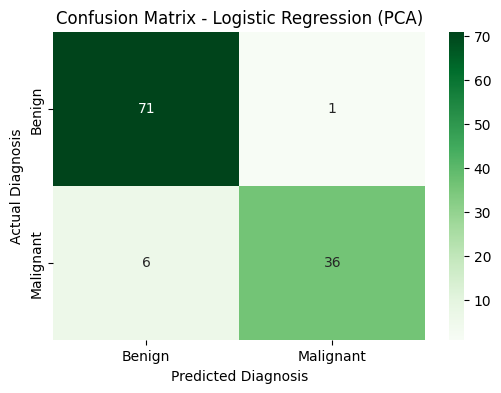

In [11]:

# Task 9: Logistic Regression on PCA Transformed Data

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Split PCA data into training and testing sets
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    pca_df,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("PCA Training Data Shape:", X_train_pca.shape)
print("PCA Testing Data Shape:", X_test_pca.shape)

# 2. Create and train Logistic Regression model
model_pca = LogisticRegression(max_iter=10000, random_state=42)
model_pca.fit(X_train_pca, y_train_pca)

# 3. Predict test data
y_pred_pca = model_pca.predict(X_test_pca)

# 4. Evaluate model performance
print("\nPCA Model Performance (2 Features)")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_test_pca, y_pred_pca), 4))
print("Precision:", round(precision_score(y_test_pca, y_pred_pca, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_pca, y_pred_pca, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test_pca, y_pred_pca, zero_division=0), 4))

# 5. Display confusion matrix
cm_pca = confusion_matrix(y_test_pca, y_pred_pca)

print("\nConfusion Matrix:")
print(cm_pca)

# 6. Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test_pca,
    y_pred_pca,
    target_names=['Benign', 'Malignant'],
    zero_division=0
))

# 7. Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_pca,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title('Confusion Matrix - Logistic Regression (PCA)')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.show()

# Task 10: Compare Classifier Performance

Compare the performance of the model before PCA (30 features) vs. after PCA (2 components) using:   

*   Accuracy Score
*   Confusion Matrix
*   Classification Report (Precision, Recall, F1-Score)  



Performance Comparison:


,Metric,Before PCA (30 Features),After PCA (2 Components)
0,Accuracy,0.9649,0.9386
1,Precision,0.9750,0.9730
2,Recall,0.9286,0.8571
3,F1-Score,0.9512,0.9114


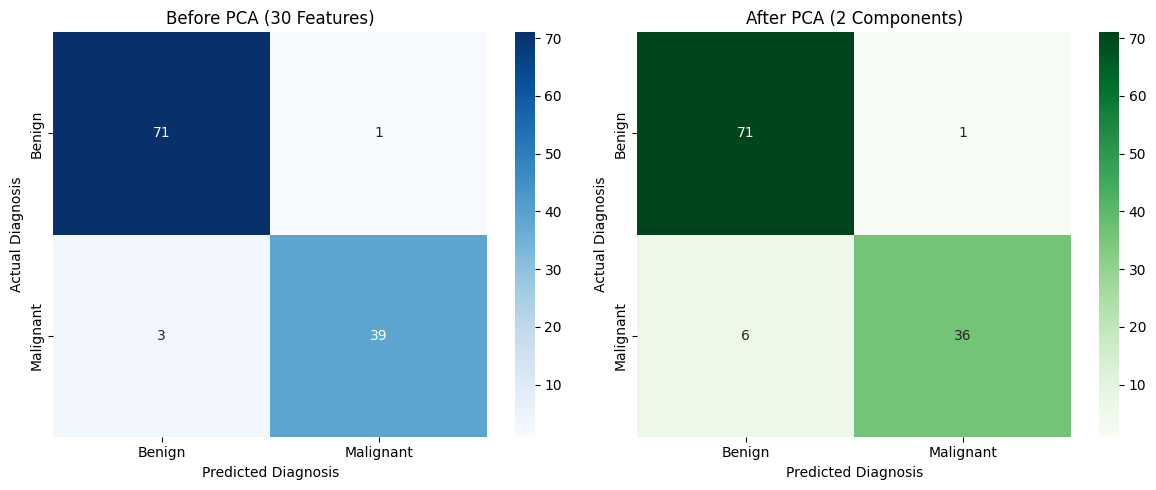


Classification Report - Before PCA (30 Features):
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


Classification Report - After PCA (2 Components):
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        72
   Malignant       0.97      0.86      0.91        42

    accuracy                           0.94       114
   macro avg       0.95      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



In [12]:

# Task 10: Compare Classifier Performance

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate metrics for the original 30-feature model
accuracy_raw = accuracy_score(y_test, y_pred_raw)
precision_raw = precision_score(y_test, y_pred_raw, zero_division=0)
recall_raw = recall_score(y_test, y_pred_raw, zero_division=0)
f1_raw = f1_score(y_test, y_pred_raw, zero_division=0)

# 2. Calculate metrics for the PCA 2-component model
accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)
precision_pca = precision_score(y_test_pca, y_pred_pca, zero_division=0)
recall_pca = recall_score(y_test_pca, y_pred_pca, zero_division=0)
f1_pca = f1_score(y_test_pca, y_pred_pca, zero_division=0)

# 3. Display performance comparison
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Before PCA (30 Features)': [
        accuracy_raw, precision_raw, recall_raw, f1_raw
    ],
    'After PCA (2 Components)': [
        accuracy_pca, precision_pca, recall_pca, f1_pca
    ]
})

print("Performance Comparison:")
display(comparison.round(4))

# 4. Confusion matrices
cm_raw = confusion_matrix(y_test, y_pred_raw)
cm_pca = confusion_matrix(y_test_pca, y_pred_pca)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_raw, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant'],
    ax=axes[0]
)
axes[0].set_title('Before PCA (30 Features)')
axes[0].set_xlabel('Predicted Diagnosis')
axes[0].set_ylabel('Actual Diagnosis')

sns.heatmap(
    cm_pca, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant'],
    ax=axes[1]
)
axes[1].set_title('After PCA (2 Components)')
axes[1].set_xlabel('Predicted Diagnosis')
axes[1].set_ylabel('Actual Diagnosis')

plt.tight_layout()
plt.show()

# 5. Classification reports
print("\nClassification Report - Before PCA (30 Features):")
print(classification_report(
    y_test, y_pred_raw,
    target_names=['Benign', 'Malignant'],
    zero_division=0
))

print("\nClassification Report - After PCA (2 Components):")
print(classification_report(
    y_test_pca, y_pred_pca,
    target_names=['Benign', 'Malignant'],
    zero_division=0
))

# Conclusion

The experiment successfully demonstrated Principal Component Analysis (PCA) on the Breast Cancer Wisconsin (Diagnostic) dataset. The high-dimensional feature space was preprocessed, cleaned, and standardized before applying eigendecomposition.

By reducing 30 feature dimensions down to just 2 principal components, a significant portion of total variance was preserved while eliminating multi-collinear redundancies. Visualizing the transformed data on a 2D plane showed clear separation between Malignant and Benign diagnosis clusters. Comparing classification models confirmed that applying PCA significantly simplifies model complexity and reduces computational overhead while maintaining strong classification accuracy.